# Construcción de Curva de Calibración (Paso a paso)
Este notebook se explaya en dar detalles para construir una curva de calibración para en otro notebook optimizar y visualizar resultados más resumidamente. Por tanto, nos centramos en el desarrollo y explicación.

## 1. Carga de datos

In [247]:
import os, re, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def find_project_root(marker='src'):
    cwd = Path(os.getcwd()).resolve()
    for parent in [cwd, *cwd.parents]:
        if (parent / marker).is_dir():
            return parent
    raise FileNotFoundError(f"No se encontro project root con '{marker}'")

PROJECT_ROOT = find_project_root()
sys.path.insert(0, str(PROJECT_ROOT))

from src.readers.keithley_dean import list_measurements, read_curve, read_all_curves
from src.plotting import plot_transfer
from src.analysis import extract_vth_for_transfers

data_folder = PROJECT_ROOT / 'data' / 'raw'

print(f"Project root: {PROJECT_ROOT}")
print(f"Data folder:   {data_folder}")
print("Archivos disponibles:")
for f in sorted(os.listdir(data_folder)):
    print(f"  {f}")

# === Seleccionar archivo hdf5 (cambiar aqui) ===
hdf5_name = "2026-10-21_sensing-edit.hdf5"
hdf5_path = PROJECT_ROOT / 'data' / 'raw' / hdf5_name

print("-"*80)
print(f"Archivo: {hdf5_name}")
print(f"Ruta:    {hdf5_path}")


Project root: /home/dibarra/Documents/egofets-project
Data folder:   /home/dibarra/Documents/egofets-project/data/raw
Archivos disponibles:
  2026-06-26_test1.hdf5
  2026-06-29_test2.1.hdf5
  2026-06-29_test2.hdf5
  2026-06-30_test3.hdf5
  2026-07-01_test3.hdf5
  2026-07-08_biosensing_10_-6.hdf5
  2026-07-08_biosensing_10_-6_v2.hdf5
  2026-07-08_test.hdf5
  2026-07-16_testkapton.hdf5
  2026-07-22_kapton_and_old.hdf5
  2026-07-22_kapton_v2.hdf5
  2026-07-22_kapton_v3.hdf5
  2026-07-23 TMTES PS Phototransistor v3.hdf5
  2026-08-13_test2_kapton_v3.hdf5
  2026-09-04_kapton_test_out.hdf5
  2026-10-02_test.hdf5
  2026-10-21_SensingB2-clear.hdf5
  2026-10-21_SensingB2.hdf5
  2026-10-21_sensing-edit.hdf5
  2026-10-21_sensing.hdf5
  2026-10-22_sensingB3-clean.hdf5
  2026-10-22_sensingB3-edit.hdf5
  2026-10-22_sensingB3.hdf5
  2026-10-23_sensingB4_v2.hdf5
  notas.txt
--------------------------------------------------------------------------------
Archivo: 2026-10-21_sensing-edit.hdf5
Ruta:    /h

In [248]:
measurement_list_dic = list_measurements(hdf5_path)

# Una medición de calibración tiene la forma
#   DnBm[_etapa]_<condición>_<sufijo>   con condición = Ref | E-XX
# Las mediciones TBE (baseline antes de estabilizar) no llevan concentración
# y se excluyen del análisis de calibración.
CALIBRATION_RE = re.compile(r'^D\d+B\d+(?:_[A-Za-z]+)?_(?:Ref|E-\d+)_\d+$')

all_transfer_measurements = [m["name"] for m in measurement_list_dic if m["mode"] == "transfer"]
transfer_measurements = [m for m in all_transfer_measurements if CALIBRATION_RE.match(m)]
baseline_measurements = [m for m in all_transfer_measurements if not CALIBRATION_RE.match(m)]

print(f"Transfer measurements ({len(all_transfer_measurements)}):")
for m in all_transfer_measurements:
    print(f"  - {m}")

print(f"\nMediciones de calibración ({len(transfer_measurements)}):")
for m in transfer_measurements:
    print(f"  - {m}")

if baseline_measurements:
    print(f"\nExcluidas (sin condición de concentración): {baseline_measurements}")


Transfer measurements (21):
  - D1B2_E-12_00
  - D1B2_E-13_00
  - D1B2_E-14_00
  - D1B2_E-15_00
  - D1B2_E-16_00
  - D1B2_E-17_00
  - D1B2_Ref_00
  - D2B2_E-12_00
  - D2B2_E-13_00
  - D2B2_E-14_00
  - D2B2_E-15_00
  - D2B2_E-16_00
  - D2B2_E-17_00
  - D2B2_Ref_00
  - D3B2_E-12_00
  - D3B2_E-13_00
  - D3B2_E-14_00
  - D3B2_E-15_00
  - D3B2_E-16_00
  - D3B2_E-17_00
  - D3B2_Ref_00

Mediciones de calibración (21):
  - D1B2_E-12_00
  - D1B2_E-13_00
  - D1B2_E-14_00
  - D1B2_E-15_00
  - D1B2_E-16_00
  - D1B2_E-17_00
  - D1B2_Ref_00
  - D2B2_E-12_00
  - D2B2_E-13_00
  - D2B2_E-14_00
  - D2B2_E-15_00
  - D2B2_E-16_00
  - D2B2_E-17_00
  - D2B2_Ref_00
  - D3B2_E-12_00
  - D3B2_E-13_00
  - D3B2_E-14_00
  - D3B2_E-15_00
  - D3B2_E-16_00
  - D3B2_E-17_00
  - D3B2_Ref_00


Las sesiones de lectura consisten en batches y dispositivos, cada batch contiene 3 dispositivos. Normalmente encontraremos archivos `.hdf5` con lecturas por batches, con la siguiente convención de nombre:

### Convención de nombres

`DnBm[_etapa]_<condición>_<sufijo>`

- `DnBm`: dispositivo y batch de fabricación (sin cambios).
- `<condición>`: `Ref` o `E-12` … `E-17` (concentración $10^{-X}$ M).
- `etapa`: opcional, distingue la serie (p. ej. `TAE`). Las mediciones `TBE` (baseline previo a la estabilización) no llevan concentración y se excluyen de la calibración.
- `sufijo`: se conserva tal cual (`_00`, `_01`, `_02`, …); mezcla repetición y secuencia de captura. La repetición canónica se resolverá en el análisis.

Procederemos con la visualización de datos.

## 2. Transfers agrupados por batch

Se detecta el batch a partir del nombre de cada medición (`D1B2_...` → `B2`) y se genera **una figura por batch**. Transfers en una sola dirección (fwd).

Batches detected: {'B2'}


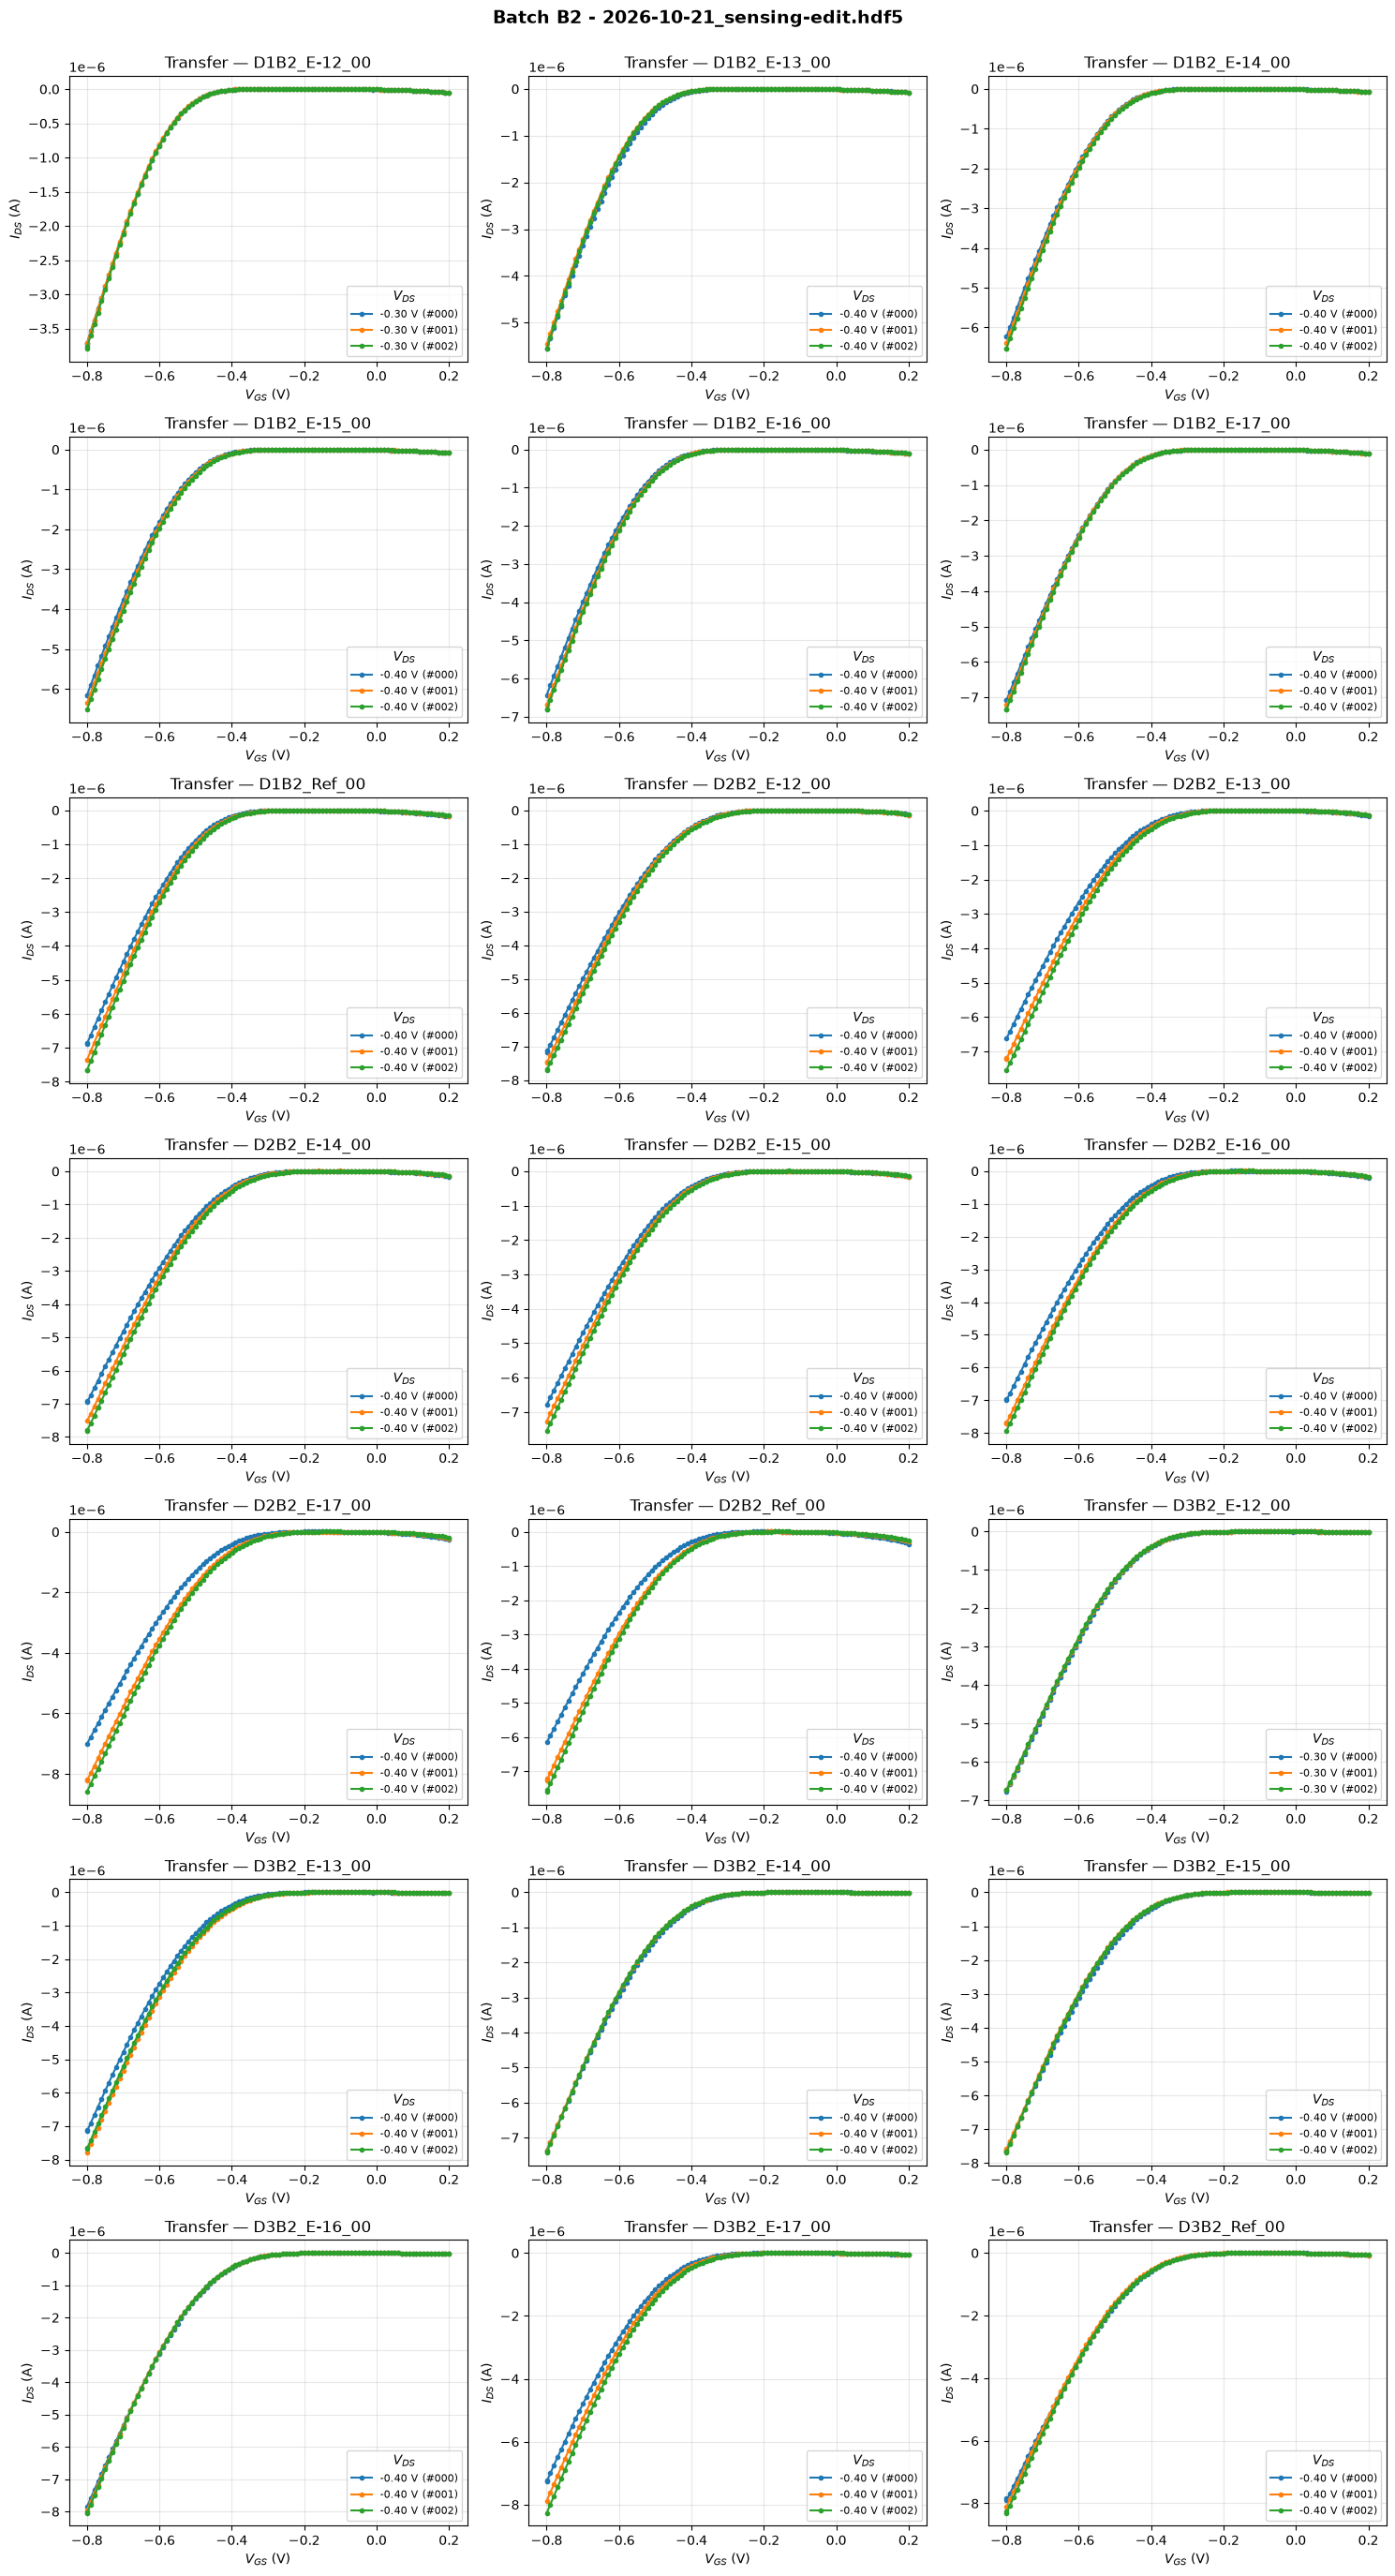

In [249]:
import re

def get_batch_name(measurement_name):
    """Extrae el batch del nombre, p. ej. 'D1B2_E-12_00' -> 'B2'."""
    match = re.match(r"^D\d+(B\d+)_", measurement_name)
    return match.group(1) if match else "No batch detected."

def parse_measurement_name(measurement_name):
    """Separa `DnBm[_etapa]_<condición>_<sufijo>`.

    'D1B2_E-12_00'     -> ('D1B2', None, 'E-12', '00')
    'D1B3_TAE_E-12_00' -> ('D1B3', 'TAE', 'E-12', '00')

    La etapa es opcional; si existe se usa como parte del identificador de
    dispositivo para no mezclar TBE y TAE en la misma normalización.
    """
    parts = measurement_name.split('_')
    device = parts[0]
    stage = parts[1] if len(parts) >= 4 else None
    cond = parts[2] if stage else parts[1]
    suffix = parts[-1]
    device_key = f"{device}_{stage}" if stage else device
    return device_key, stage, cond, suffix


def plot_grid(hdf5_path, measurements, plot_func, ncols=3, figsize_per=(5, 4), title_suffix=None):
    n = len(measurements)
    nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(figsize_per[0]*ncols, figsize_per[1]*nrows))
    axes_flat = np.array(axes).flatten() if n > 1 else np.array([axes])
    for ax, m_name in zip(axes_flat, measurements):
        plot_func(hdf5_path, m_name, ax=ax, direction='fwd') # Solo fordward para la calibración.
    for ax in axes_flat[len(measurements):]:
        ax.set_visible(False)
    if title_suffix:
        fig.suptitle(title_suffix, fontsize=14, fontweight="bold")
        fig.tight_layout(rect=[0, 0, 1, 0.98])
    else:
        fig.tight_layout()
    return fig

batches = set(get_batch_name(m) for m in transfer_measurements)
print(f"Batches detected: {batches}")

title = f'Batch {", ".join(batches)} - {hdf5_name}' if len(batches) >= 1 else None

fig = plot_grid(hdf5_path, transfer_measurements, plot_transfer, title_suffix=title)
plt.show()


## 3. Agrupación de datos y estadística

Cada condición se mide en varias réplicas técnicas dentro de una misma medición. Al
agrupar las lecturas hay dos fuentes de dispersión que conviene no mezclar:

- **Repetibilidad**: dispersión entre las réplicas de una misma medición (mismo
  dispositivo, misma condición, misma sesión). Mide cuánto varía la lectura cuando
  nada cambia deliberadamente.
- **Reproducibilidad (entre dispositivos)**: dispersión entre las medias de los
  dispositivos para una misma condición. Incluye variabilidad de fabricación y de
  contacto.

En este notebook las barras de error corresponden a la **repetibilidad** (SD de las
réplicas técnicas). Los ajustes se hacen por dispositivo, sin promediarlos entre sí.

El análisis se organiza en tres pasos:

1. **3.1 Dispersión de un punto**: leer $I_{DS}$ en un único $V_{READ}$.
2. **3.2 Dispersión de una ventana**: promediar $I_{DS}$ alrededor de $V_{READ}$
   para reducir la sensibilidad al ruido.
3. **3.3 Ajuste lineal-log**: ajustar $R$ frente a $\log_{10} C$ y extraer la
   sensibilidad.

Antes de comparar concentraciones, ambas lecturas se normalizan contra la `Ref` del
mismo dispositivo (respuesta $R$, definida en 3.1).


### 3.1 Dispersión de un punto

El método más directo consiste en leer $I_{DS}$ en un único $V_{GS}=V_{READ}$ sobre
cada curva. Para cada medición (dispositivo + condición) se promedian las réplicas
técnicas y se obtiene **un punto** de la curva de calibración. Si una condición se
midió varias veces (`_00`, `_01`, …), sus mediciones se agrupan antes de promediar.

El primer problema es elegir $V_{READ}$ de forma objetiva. La respuesta del
transistor es máxima donde la curva transfer tiene mayor pendiente, así que el punto
se elige a partir de la transconductancia.


#### Transconductancia y elección de $V_{READ}$

La transconductancia mide cuánto cambia la corriente de drenador-fuente ante un
cambio de la tensión puerta-fuente:

$$
g_m = \frac{dI_{DS}}{dV_{GS}}
$$

En estos transistores $g_m$ no es constante: en subumbral crece con $I_{DS}$ y en
saturación crece con $V_{GS}-V_{th}$. La zona de mayor $|g_m|$ es, por tanto, la más
sensible a un cambio de corriente y el mejor lugar para leer la respuesta.

El cálculo se hace sobre la rama forward. `_select_direction(..., 'fwd')` conserva
el punto de retorno del barrido, que repite el $V_{GS}$ extremo con una diferencia
de $\sim10^{-5}$ V; si no se elimina, `np.gradient` divide por un paso casi nulo y
genera un pico artificial de $g_m$. Por eso se ordena $V_{GS}$ de forma ascendente y
se descarta ese punto duplicado antes de derivar.

El punto de lectura se fija **por batch** como la mediana del $V_{GS}$ donde
$|g_m|$ es máxima en todas las réplicas. Así todas las curvas del batch se leen en
el mismo $V_{GS}$ y la elección del punto no se mezcla con la respuesta al analito.


Transconductancia máxima: V_gs = -0.780 V, g_m = 2.46e-05 A/V


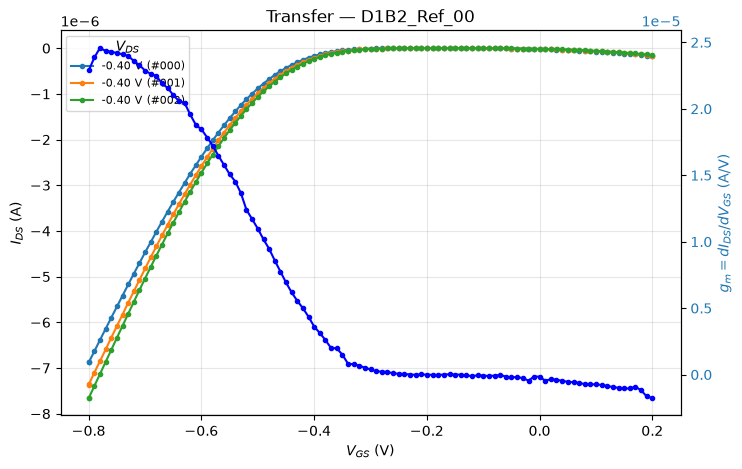

,batch,measurement,v_read,gm_max,n_replicas
0,B2,D1B2_E-12_00,-0.799510,0.000019,3
1,B2,D1B2_E-13_00,-0.789542,0.000024,3
2,B2,D1B2_E-14_00,-0.799508,0.000025,3
3,B2,D1B2_E-15_00,-0.799515,0.000025,3
4,B2,D1B2_E-16_00,-0.779803,0.000026,3
5,B2,D1B2_E-17_00,-0.769649,0.000026,3
6,B2,D1B2_Ref_00,-0.769582,0.000026,3
7,B2,D2B2_E-12_00,-0.779803,0.000023,3
8,B2,D2B2_E-13_00,-0.779736,0.000022,3
9,B2,D2B2_E-14_00,-0.759726,0.000023,3


V_READ por batch: {'B2': -0.78}
Usando V_READ = -0.78 V para el batch B2


In [250]:
# === Transconductancia y elección de V_READ ===
# Curvas con menos puntos que este umbral se consideran adquisiciones fallidas
# y se descartan de todos los cálculos.
MIN_POINTS = 5
# Reproduce el análisis de 01_transfer_analysis.ipynb:
#   g_m = dI_DS/dV_GS  ->  V_READ = V_GS donde |g_m| es máxima.

def clean_forward_branch(v_gs, i_ds, rel_tol=0.25):
    """Ordena V_GS ascendente y elimina el punto de retorno duplicado.

    `_select_direction(..., 'fwd')` incluye el punto de giro del barrido, que
    puede repetir el V_GS del borde con una diferencia de ~1e-5 V. Ese punto
    haría que np.gradient dividiera por un paso casi nulo y generara un pico
    artificial de g_m. Se descarta comparando con el paso mediano del barrido.
    """
    v = np.asarray(v_gs, dtype=float)
    i = np.asarray(i_ds, dtype=float)
    order = np.argsort(v)
    v, i = v[order], i[order]
    if v.size < 3:
        return v, i
    step = float(np.median(np.abs(np.diff(v))))
    keep = np.concatenate(([True], np.abs(np.diff(v)) > rel_tol * step))
    return v[keep], i[keep]


def forward_gm(v_gs, i_ds):
    """Devuelve (V_GS, I_DS, g_m) de la rama forward ya limpia.

    Si tras limpiar quedan menos de 2 puntos, g_m se devuelve vacío.
    """
    v, i = clean_forward_branch(v_gs, i_ds)
    if v.size < 2:
        return v, i, np.array([])
    return v, i, np.gradient(i, v)


def plot_transfer_gm(hdf5_path, m_name, ax=None, direction='fwd'):
    """Curva transfer + g_m en eje gemelo, como en 01_transfer_analysis.ipynb."""
    fig, ax = plot_transfer(hdf5_path, m_name, direction=direction, ax=ax)
    v_gs, i_ds = read_curve(hdf5_path, m_name, direction=direction)
    v, i, gm = forward_gm(v_gs, i_ds)

    sec = ax.twinx()
    sec.plot(v, gm, 'o-', ms=3, color='blue', label='Transconductance')
    sec.set_ylabel(r'$g_m = dI_{DS}/dV_{GS}$ (A/V)', color='C0')
    sec.tick_params(axis='y', labelcolor='C0')
    ax.grid(True, alpha=0.3)

    idx = int(np.argmax(np.abs(gm)))
    return {'fig': fig, 'ax': ax, 'ax_gm': sec,
            'v_gs': v, 'i_ds': i, 'gm': gm,
            'v_read': float(v[idx]), 'gm_max': float(abs(gm[idx]))}


# --- Demostración sobre una medición ---
m_demo = 'D1B2_Ref_00' if 'D1B2_Ref_00' in transfer_measurements else transfer_measurements[0]
gm_demo = plot_transfer_gm(hdf5_path, m_demo)
print(f"Transconductancia máxima: V_gs = {gm_demo['v_read']:.3f} V, g_m = {gm_demo['gm_max']:.2e} A/V")
plt.show()


# --- V_READ por batch: mediana del V_GS de |g_m| máxima ---
gm_rows = []
for m in transfer_measurements:
    for k, c in enumerate(read_all_curves(hdf5_path, m, direction='fwd'), start=1):
        if len(c['v_gs']) < MIN_POINTS:
            continue
        v, i, gm = forward_gm(c['v_gs'], c['i_ds'])
        if gm.size == 0:
            continue
        idx = int(np.argmax(np.abs(gm)))
        gm_rows.append({
            'batch': get_batch_name(m),
            'measurement': m,
            'replica': k,
            'v_read': float(v[idx]),
            'gm_max': float(abs(gm[idx])),
        })

df_gm = pd.DataFrame(gm_rows)
df_gm_summary = (df_gm
                 .groupby(['batch', 'measurement'])
                 .agg(v_read=('v_read', 'median'),
                      gm_max=('gm_max', 'median'),
                      n_replicas=('replica', 'count'))
                 .reset_index())
display(df_gm_summary)

V_READ_BY_BATCH = (df_gm.groupby('batch')['v_read'].median()
                   .round(2).to_dict())
print('V_READ por batch:', V_READ_BY_BATCH)

batches_file = df_gm['batch'].unique()
if len(batches_file) != 1:
    raise ValueError(f"Este notebook espera un solo batch por archivo; hay {list(batches_file)}")
BATCH = batches_file[0]
V_READ = V_READ_BY_BATCH[BATCH]
print(f"Usando V_READ = {V_READ:.2f} V para el batch {BATCH}")


#### Visualización del punto de lectura

Para comprobar que la elección es razonable, se dibuja cada curva forward y se
superpone una **estrella roja por réplica**, interpolada en $V_{READ}$.

Si las estrellas de una misma condición quedan juntas y sobre la zona de mayor
pendiente, el método de un solo punto (3.1) es fiable. Si quedan dispersas, conviene
pasar al método de ventana (3.2).

Como $V_{READ}$ cae en el borde negativo del barrido, en 3.2 la ventana se toma
**hacia el interior**.


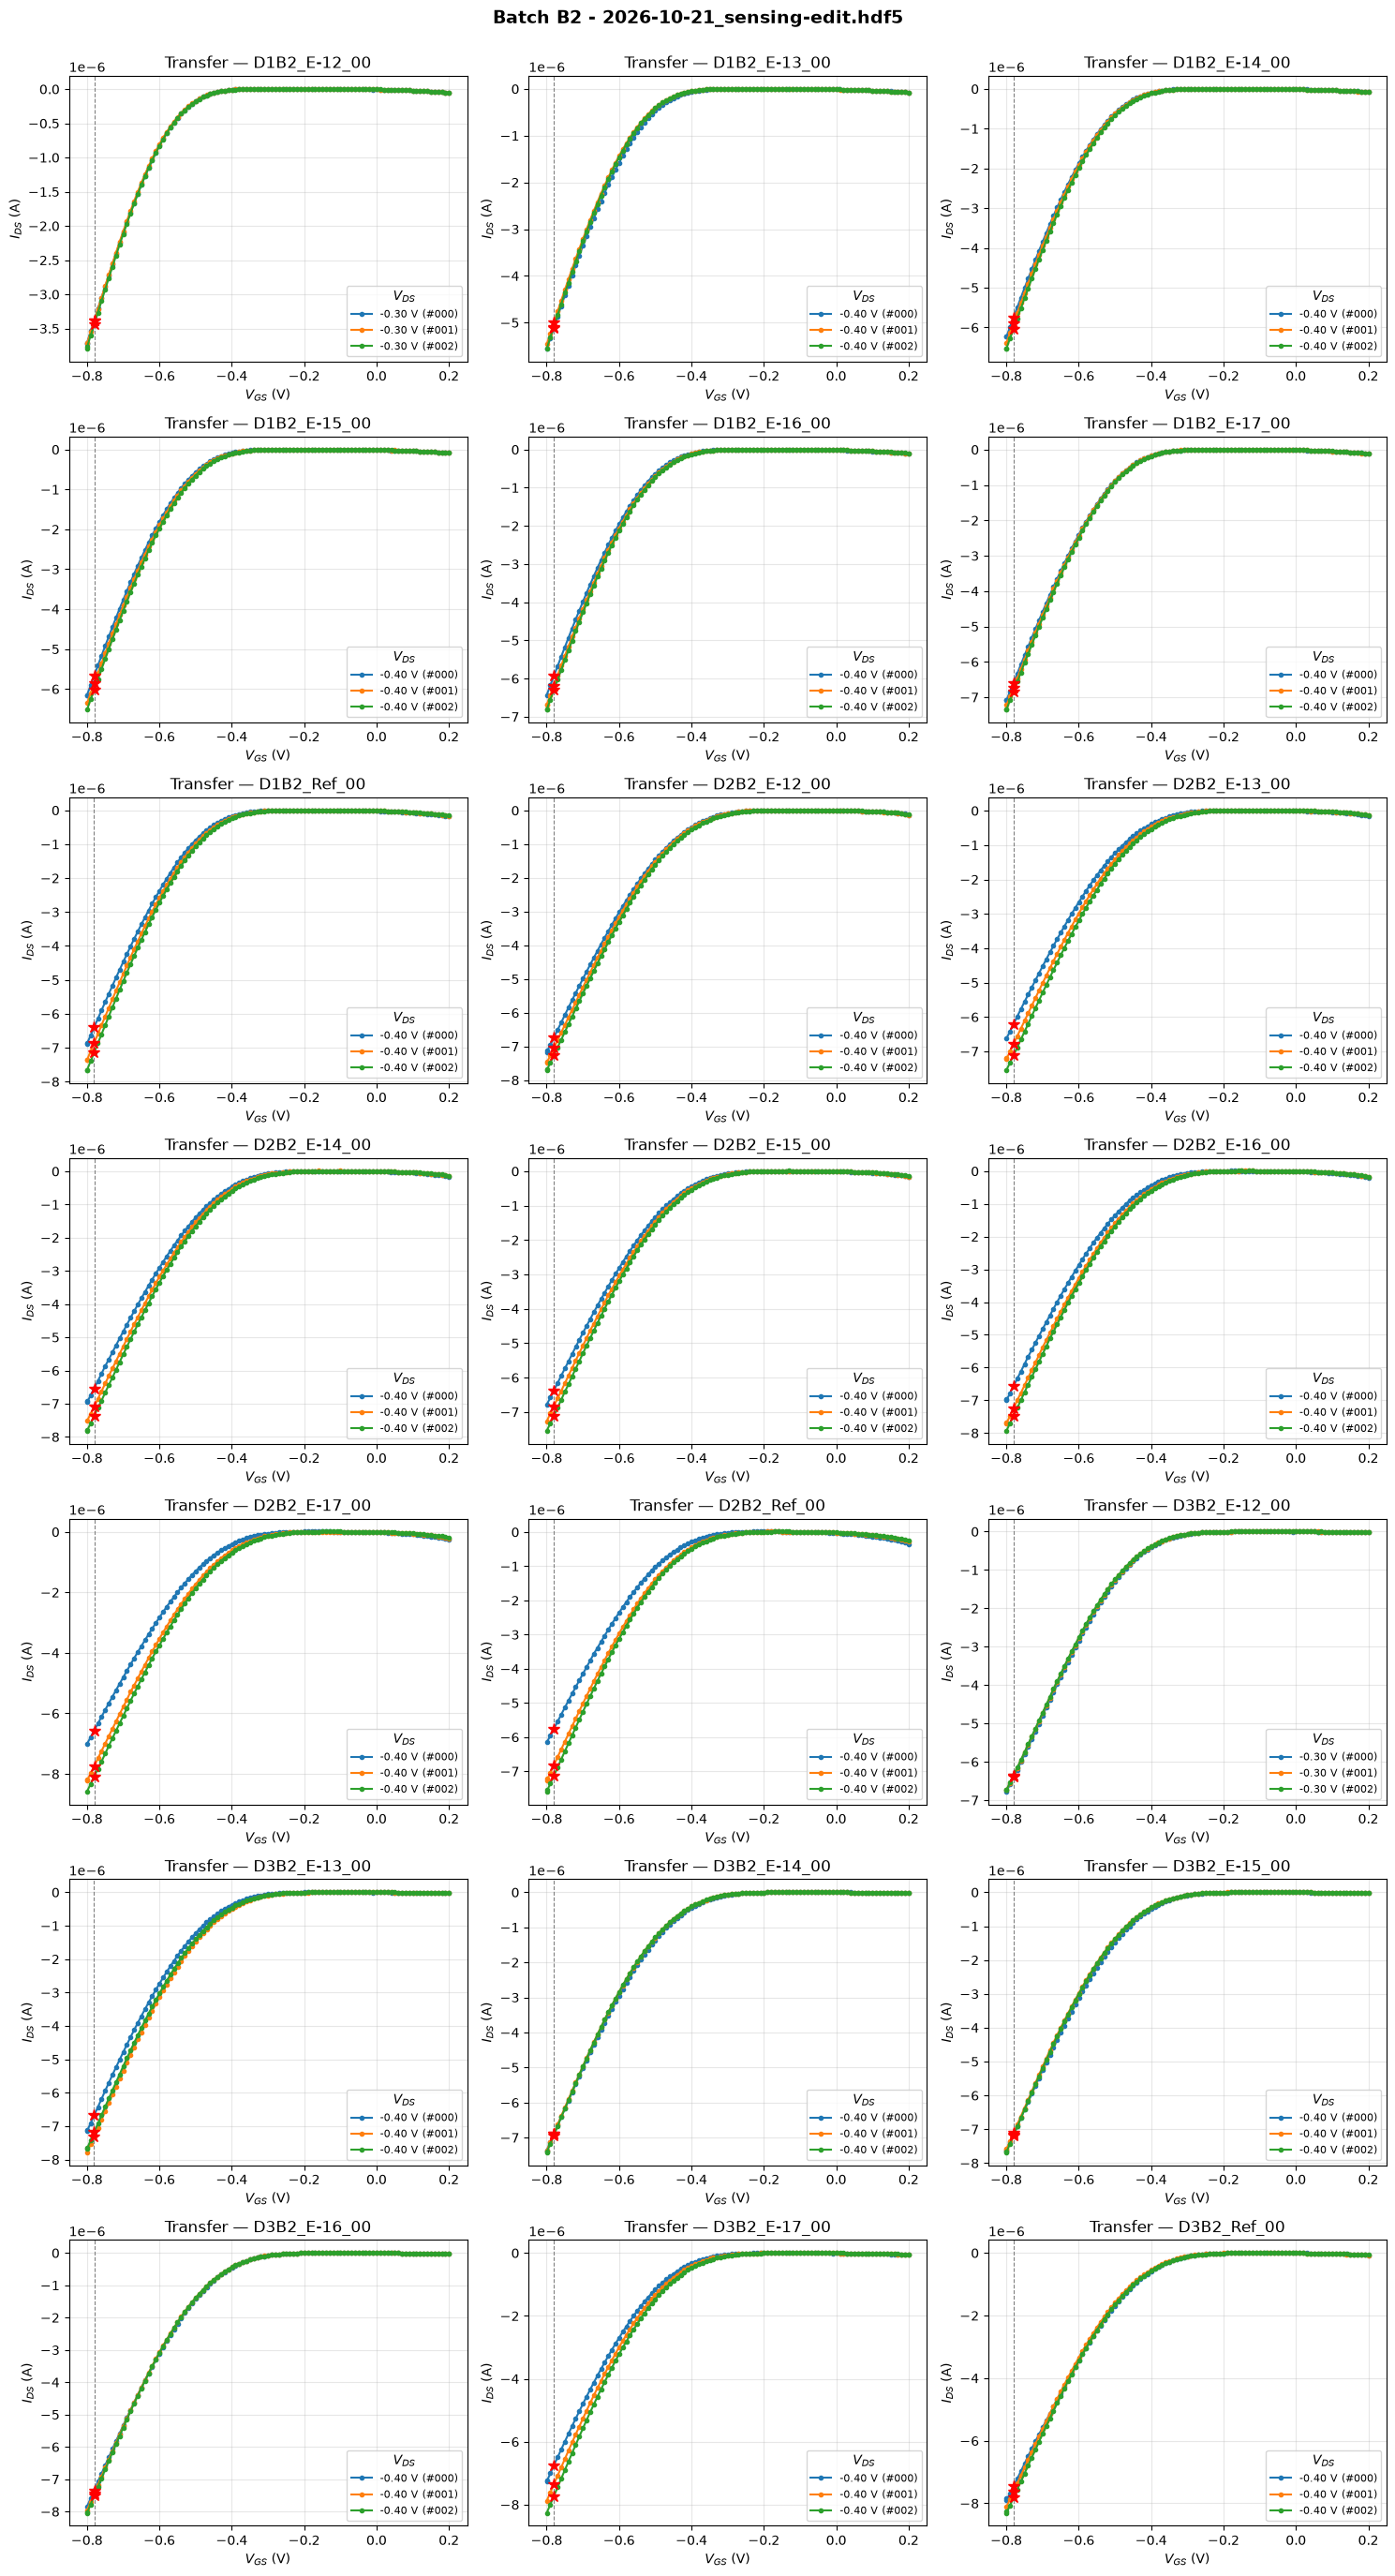

In [251]:
def plot_transfer_vread(hdf5_path, m_name, ax=None, direction='fwd', v_read=None):
    """Curvas forward de una medición + punto interpolado en V_READ.

    Firma compatible con plot_grid, que la llama como:
        plot_func(hdf5_path, m_name, ax=ax, direction='fwd')
    """
    if v_read is None:
        v_read = V_READ

    # 1) Curvas: reutilizamos el estilo y la leyenda de plot_transfer.
    plot_transfer(hdf5_path, m_name, direction=direction, ax=ax)

    # 2) Un punto por réplica: interpolamos I_DS en V_READ sobre cada curva.
    for c in read_all_curves(hdf5_path, m_name, direction=direction):
        if len(c['v_gs']) < MIN_POINTS:
            continue
        v, i = clean_forward_branch(c['v_gs'], c['i_ds'])
        i_read = float(np.interp(v_read, v, i))
        ax.plot(v_read, i_read, 'r*', ms=9, zorder=5)

    ax.axvline(v_read, color='gray', ls='--', lw=0.8)
    return ax

fig = plot_grid(hdf5_path, transfer_measurements, plot_transfer_vread, title_suffix=title)
plt.show()

# --- Opcional: un solo dispositivo ---
# sub_ms = [m for m in transfer_measurements if m.startswith('D1B2')]
# plot_grid(hdf5_path, sub_ms, plot_transfer_vread, title_suffix='D1B2')
# plt.show()


#### Extracción de la lectura

Para cada réplica se interpola $I_{DS}$ en $V_{READ}$ (la rama forward ya está
ordenada) y se calcula la media y la SD de las réplicas de esa medición. Si una
condición tiene varias mediciones (`_00`, `_01`, …), se promedian sus medias y se
agrupa la dispersión; el resultado es una fila por dispositivo y condición.


In [252]:
# === 3.1 Dispersión de un punto ===
# Método del artículo: leer I_DS en un V_GS fijo (un punto por curva),
# promediar las réplicas de cada medición y normalizar contra la Ref
# del mismo dispositivo: R = (I_DS - I_DS,0) / I_DS,0.

def i_ds_at(v_gs, i_ds, v_read):
    """I_DS interpolado linealmente en v_read (rama de ida ya recortada)."""
    order = np.argsort(v_gs)  # eje creciente para np.interp
    return float(np.interp(v_read, v_gs[order], i_ds[order]))

def cond_conc(cond):
    """'E-12' -> 1e-12 M; 'Ref' -> None."""
    return None if cond == 'Ref' else 10.0 ** (-int(cond.split('-')[1]))

def _safe_get(seq, k):
    """Elemento k de seq o NaN si no existe."""
    return float(seq[k]) if len(seq) > k else float('nan')

def _pooled_sd(s):
    """Combina SD de varias mediciones: sqrt(media de varianzas)."""
    s = np.asarray(s, dtype=float)
    return float(np.sqrt(np.nanmean(s ** 2))) if s.size else float('nan')

def collapse_conditions(df_raw):
    """Una fila por dispositivo+condición a partir de una fila por medición.

    Si una condición se midió varias veces (sufijos _00, _01, ...), se promedian
    las medias de cada medición y se agrupa su dispersión técnica.
    """
    # groupby(['...', 'conc']) descartaría las filas Ref (conc=None), por eso
    # se agrupa por device+condition y se conserva conc con 'first'.
    return (df_raw
            .groupby(['device', 'condition'], as_index=False)
            .agg(measurement=('measurement', 'first'),
                 conc=('conc', 'first'),
                 n_measurements=('measurement', 'count'),
                 n_replicas=('n_replicas', 'sum'),
                 mean=('mean', 'mean'),
                 sd=('sd', _pooled_sd)))

# --- Extracción: un I_DS por curva (todas las réplicas de cada medición) ---
rows = []
for m in transfer_measurements:
    curves = [c for c in read_all_curves(hdf5_path, m, direction='fwd')
              if len(c['v_gs']) >= MIN_POINTS]
    pts = np.array([i_ds_at(c['v_gs'], c['i_ds'], V_READ) for c in curves],
                   dtype=float)
    if pts.size == 0:
        continue
    dev, _, cond, _ = parse_measurement_name(m)
    rows.append({
        'measurement': m,
        'device': dev,
        'condition': cond,
        'conc': cond_conc(cond),
        'n_replicas': int(pts.size),
        'i1': _safe_get(pts, 0), 'i2': _safe_get(pts, 1), 'i3': _safe_get(pts, 2),
        'mean': float(np.mean(pts)),
        'sd': float(np.std(pts, ddof=1)) if pts.size > 1 else 0.0,
    })

df_pts_raw = pd.DataFrame(rows)
df_pts = collapse_conditions(df_pts_raw)



#### La respuesta normalizada $R$

La curva de calibración no usa la corriente absoluta $I_{DS}$, sino una respuesta
relativa que elimina la escala propia de cada dispositivo:

$$
R = \frac{I_{DS} - I_{DS,0}}{I_{DS,0}}
$$

donde:

- $I_{DS}$ es la corriente leída a $V_{GS} = V_{READ}$ para una concentración dada
  (media de las réplicas de esa medición).
- $I_{DS,0}$ es la corriente leída en la **misma** $V_{GS}$ para la medida de
  referencia `Ref` del **mismo dispositivo**, es decir, la línea base sin analito.

**Interpretación de cada término**

| Término | Significado |
|---|---|
| $I_{DS} - I_{DS,0}$ | Cambio absoluto de corriente producido por el analito. |
| $I_{DS,0}$ | Corriente de referencia; fija la escala del dispositivo. |
| $R$ | Cambio relativo, adimensional. $R=0$ indica que no hay cambio respecto al blanco. |

Normalizar contra el `Ref` del mismo dispositivo es lo que permite comparar
dispositivos distintos: cada uno tiene una corriente base diferente (contactos,
geometría, espesor) y dividir por su propio $I_{DS,0}$ elimina ese offset. Si se
usara $I_{DS}$ en crudo, las diferencias entre dispositivos mezclarían la respuesta
al analito con la variabilidad de fabricación.

**Signo de $R$**

En estos EGOFETs la corriente es negativa. Si al aumentar la concentración disminuye
$|I_{DS}|$, entonces $I_{DS} - I_{DS,0} > 0$ pero $I_{DS,0} < 0$, y el cociente da
$R < 0$. El signo negativo no es un error: indica la dirección de la respuesta. La
sensibilidad es la pendiente de $R$ frente a $\log_{10} C$ y hereda ese signo.

> Si se prefiere una respuesta positiva, se puede definir explícitamente
> $R' = -R = (I_{DS,0} - I_{DS})/I_{DS,0}$. Lo importante es usar la misma definición
> en la gráfica, en el ajuste y en el cálculo del LoD.

**Incertidumbre**

La dispersión de $R$ se obtiene propagando la SD de las réplicas de $I_{DS}$ y
tratando $I_{DS,0}$ como constante:

$$
s_R = \frac{s_{I_{DS}}}{|I_{DS,0}|}
$$

Si se quiere incluir la incertidumbre del `Ref`, se usa la propagación completa:

$$
s_R \approx |R| \sqrt{\left(\frac{s_{I_{DS}}}{I_{DS}-I_{DS,0}}\right)^2
+ \left(\frac{s_{I_{DS,0}}}{I_{DS,0}}\right)^2}
$$

En este notebook se usa la primera aproximación, que es la que corresponde a las
barras de error de las gráficas.


In [253]:
# --- Normalización contra la Ref del mismo dispositivo ---
df_pts['R'] = np.nan
df_pts['R_sd'] = np.nan
for dev, grp in df_pts.groupby('device'):
    i_ref = grp.loc[grp['condition'] == 'Ref', 'mean'].iloc[0]
    df_pts.loc[grp.index, 'R'] = (grp['mean'] - i_ref) / i_ref
    # Propagación a 1er orden (Ref tratada como constante)
    df_pts.loc[grp.index, 'R_sd'] = grp['sd'] / abs(i_ref)

df_pts



,device,condition,measurement,conc,n_measurements,n_replicas,mean,sd,R,R_sd
0,D1B2,E-12,D1B2_E-12_00,1.000000e-12,1,3,-0.000003,3.265919e-08,-0.499187,0.004805
1,D1B2,E-13,D1B2_E-13_00,1.000000e-13,1,3,-0.000005,5.671331e-08,-0.254678,0.008344
2,D1B2,E-14,D1B2_E-14_00,1.000000e-14,1,3,-0.000006,1.403330e-07,-0.133398,0.020647
3,D1B2,E-15,D1B2_E-15_00,1.000000e-15,1,3,-0.000006,1.744866e-07,-0.139807,0.025672
4,D1B2,E-16,D1B2_E-16_00,1.000000e-16,1,3,-0.000006,1.858498e-07,-0.096958,0.027343
5,D1B2,E-17,D1B2_E-17_00,1.000000e-17,1,3,-0.000007,1.219504e-07,-0.011745,0.017942
6,D1B2,Ref,D1B2_Ref_00,NaN,1,3,-0.000007,3.763526e-07,-0.000000,0.055371
7,D2B2,E-12,D2B2_E-12_00,1.000000e-12,1,3,-0.000007,2.642957e-07,0.067871,0.040233
8,D2B2,E-13,D2B2_E-13_00,1.000000e-13,1,3,-0.000007,4.581591e-07,0.020422,0.069744
9,D2B2,E-14,D2B2_E-14_00,1.000000e-14,1,3,-0.000007,4.224154e-07,0.065219,0.064302


#### Visualización y primera curva de calibración

La primera figura muestra, para cada dispositivo, las curvas de todas las
condiciones con su punto de lectura y la media de la condición. La segunda es la
primera curva de calibración, $R$ frente a $\log_{10} C$; la recta se ajusta en 3.3.


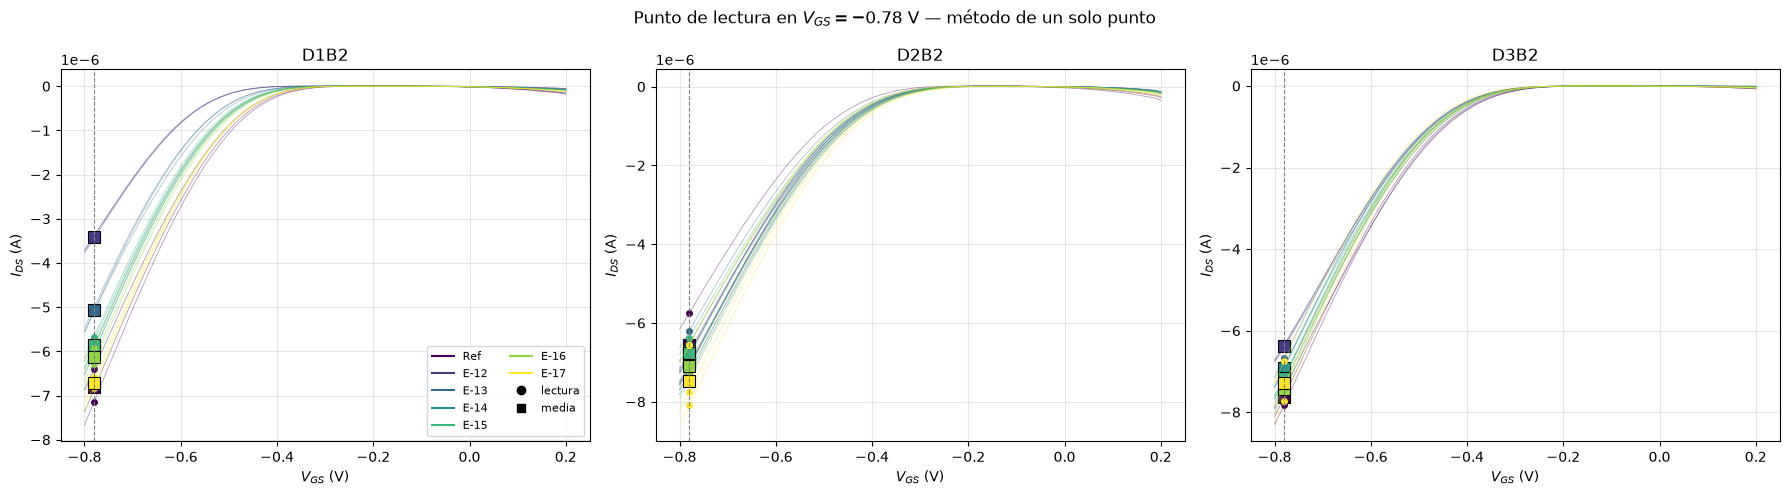

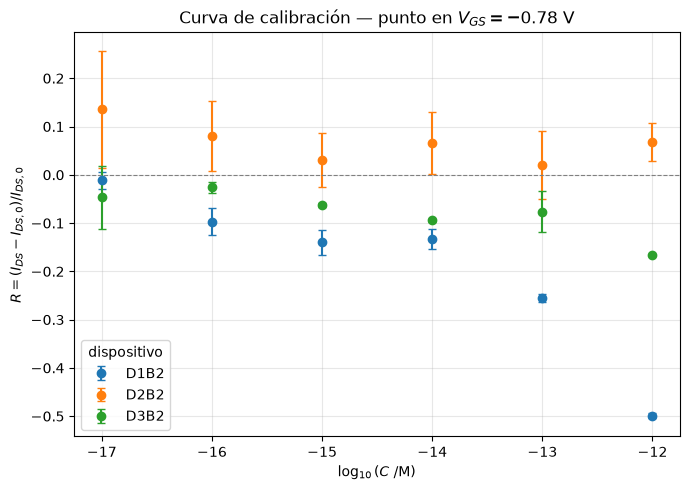

In [254]:
# --- Visualización: un punto por lectura sobre cada curva (por dispositivo) ---
condition_order = ['Ref', 'E-12', 'E-13', 'E-14', 'E-15', 'E-16', 'E-17']
cmap = plt.cm.viridis
cond_color = {cond: cmap(k / (len(condition_order) - 1))
              for k, cond in enumerate(condition_order)}

devices = sorted(df_pts['device'].unique())
fig, axes = plt.subplots(1, len(devices), figsize=(6 * len(devices), 5))
if len(devices) == 1:
    axes = [axes]

for ax, dev in zip(axes, devices):
    for cond in condition_order:
        sub_raw = df_pts_raw[(df_pts_raw['device'] == dev) &
                             (df_pts_raw['condition'] == cond)]
        sub = df_pts[(df_pts['device'] == dev) & (df_pts['condition'] == cond)]
        if sub.empty:
            continue
        color = cond_color[cond]
        # Curvas y lecturas de todas las mediciones de esa condición
        for _, row in sub_raw.iterrows():
            for c in read_all_curves(hdf5_path, row['measurement'], direction='fwd'):
                ax.plot(c['v_gs'], c['i_ds'], '-', lw=0.6, color=color, alpha=0.4)
                ax.plot(V_READ, i_ds_at(c['v_gs'], c['i_ds'], V_READ), 'o',
                        ms=4, color=color)
        # Media de la condición
        ax.plot(V_READ, sub['mean'].iloc[0], 's', ms=8, color=color,
                markeredgecolor='k', markeredgewidth=0.8)
    ax.axvline(V_READ, color='gray', ls='--', lw=0.8)
    ax.set_title(dev)
    ax.set_xlabel(r'$V_{GS}$ (V)')
    ax.set_ylabel(r'$I_{DS}$ (A)')
    ax.grid(True, alpha=0.3)

# Leyenda de condiciones y marcadores (solo en el primer panel)
ax0 = axes[0]
for cond in condition_order:
    ax0.plot([], [], color=cond_color[cond], label=cond)
ax0.plot([], [], 'o', color='k', label='lectura')
ax0.plot([], [], 's', color='k', markeredgecolor='k', label='media')
ax0.legend(fontsize=8, ncol=2, loc='best')

fig.suptitle(f'Punto de lectura en $V_{{GS}}={V_READ}$ V — método de un solo punto')
fig.tight_layout()
plt.show()

# --- Primera curva de calibración: R vs log10(C) ---
cal = df_pts[df_pts['condition'] != 'Ref'].copy()
cal['logC'] = np.log10(cal['conc'])

fig, ax = plt.subplots(figsize=(7, 5))
for dev, grp in cal.groupby('device'):
    grp = grp.sort_values('logC')
    ax.errorbar(grp['logC'], grp['R'], ls='none', yerr=grp['R_sd'],
                marker='o', capsize=3, label=dev)

ax.axhline(0, color='gray', ls='--', lw=0.8)
ax.set_xlabel(r'$\log_{10}(C\ /\mathrm{M})$')
ax.set_ylabel(r'$R = (I_{DS} - I_{DS,0}) / I_{DS,0}$')
ax.set_title(f'Curva de calibración — punto en $V_{{GS}}={V_READ}$ V')
ax.grid(True, alpha=0.3)
ax.legend(title='dispositivo')
fig.tight_layout()
plt.show()


### 3.2 Dispersión de una ventana de puntos

El método de un solo punto (3.1) interpola $I_{DS}$ en un único $V_{GS}$. Si ese
punto cae sobre una fluctuación de ruido, la lectura se desvía. Para ser más
robustos, **promediamos $I_{DS}$ sobre una ventana** de $V_{GS}$ que arranca en
$V_{READ}$.

$V_{READ}$ cae en el **borde negativo** del barrido (allí $|g_m|$ es máxima), así que
una ventana centrada se saldría del rango medido. Por eso la ventana es
**unilateral hacia el interior** del barrido:

- `V_WINDOW`: ancho de la ventana (en V). La ventana es `[V_READ, V_READ + V_WINDOW]`.
- `V_WINDOW_SIDE='inward'` elige automáticamente el lado interior según el borde en
  el que caiga $V_{READ}$ (`outward` y `both` quedan disponibles).
- Para cada curva (réplica) se calcula la **media** de $I_{DS}$ en los puntos que
  caen dentro de la ventana.
- El resto (media de las réplicas, SD y normalización contra la `Ref`) es idéntico
  a 3.1.


Ventana inward: [-0.780, -0.730] V  ->  5 puntos
I_DS punto único (interp.): -3.383e-06 A
I_DS media de ventana     : -3.049e-06 A


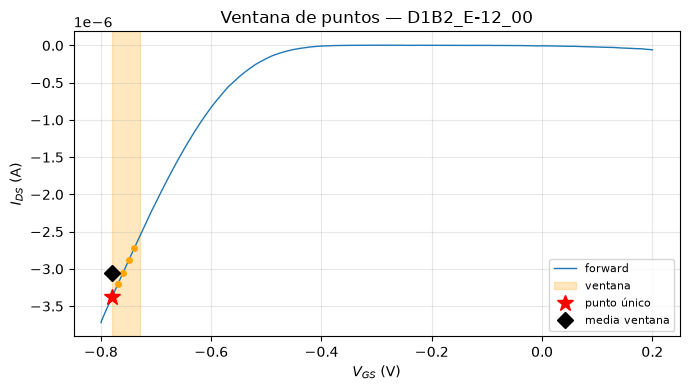

In [255]:
# === 3.2 Dispersión de una ventana de puntos ===
# Promediamos I_DS sobre una ventana de V_GS (en vez de interpolar un solo punto),
# para ser menos sensibles al ruido de un único punto.

V_WINDOW = 0.05           # ancho de la ventana (V)
V_WINDOW_SIDE = 'inward'  # 'inward' (hacia el interior), 'outward' o 'both'


def window_bounds(v_gs, v_center, half_width, side='inward'):
    """Extremos de la ventana de lectura.

    `inward` toma los puntos que quedan hacia el interior del barrido desde
    V_READ. Como V_READ cae en el borde negativo, la ventana va hacia V_GS
    crecientes y no se sale del rango medido.
    """
    v = np.asarray(v_gs, dtype=float)
    at_low_edge = abs(v_center - v.min()) <= abs(v_center - v.max())
    if side == 'both':
        return v_center - half_width, v_center + half_width
    if side == 'inward':
        return (v_center, v_center + half_width) if at_low_edge \
               else (v_center - half_width, v_center)
    if side == 'outward':
        return (v_center - half_width, v_center) if at_low_edge \
               else (v_center, v_center + half_width)
    raise ValueError(f"V_WINDOW_SIDE='{side}' no soportado")


def window_mask(v_gs, v_center, half_width, side='inward'):
    lo, hi = window_bounds(v_gs, v_center, half_width, side)
    v = np.asarray(v_gs, dtype=float)
    return (v >= lo) & (v <= hi)


def i_ds_window_mean(v_gs, i_ds, v_center, half_width, side='inward'):
    """Media de I_DS en la ventana de lectura."""
    mask = window_mask(v_gs, v_center, half_width, side)
    if not mask.any():
        return float('nan')
    return float(np.mean(np.asarray(i_ds)[mask]))


# --- Sanity check: ventana sobre una curva ---
m_demo = transfer_measurements[0]
c_demo = next(c for c in read_all_curves(hdf5_path, m_demo, direction='fwd')
              if len(c['v_gs']) >= MIN_POINTS)
v, i = c_demo['v_gs'], c_demo['i_ds']
mask = window_mask(v, V_READ, V_WINDOW, V_WINDOW_SIDE)
lo, hi = window_bounds(v, V_READ, V_WINDOW, V_WINDOW_SIDE)

print(f'Ventana {V_WINDOW_SIDE}: [{lo:.3f}, {hi:.3f}] V  ->  {mask.sum()} puntos')
print(f'I_DS punto único (interp.): {i_ds_at(v, i, V_READ):.3e} A')
print(f'I_DS media de ventana     : {np.mean(i[mask]):.3e} A')

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(v, i, '-', lw=1, label='forward')
ax.axvspan(lo, hi, color='orange', alpha=0.25, label='ventana')
ax.plot(v[mask], i[mask], 'o', ms=4, color='orange')
ax.plot(V_READ, i_ds_at(v, i, V_READ), 'r*', ms=12, label='punto único')
ax.plot(V_READ, np.mean(i[mask]), 'kD', ms=8, label='media ventana')
ax.set_xlabel(r'$V_{GS}$ (V)')
ax.set_ylabel(r'$I_{DS}$ (A)')
ax.set_title(f'Ventana de puntos — {m_demo}')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()



#### Extracción y comparación

Cada réplica se reduce a la media de $I_{DS}$ dentro de su ventana. La media de las
réplicas, la SD y la normalización contra la `Ref` se calculan igual que en 3.1, de
modo que ambas curvas son directamente comparables.

La figura final superpone los dos métodos para decidir si la ventana aporta
estabilidad sin cambiar la tendencia.


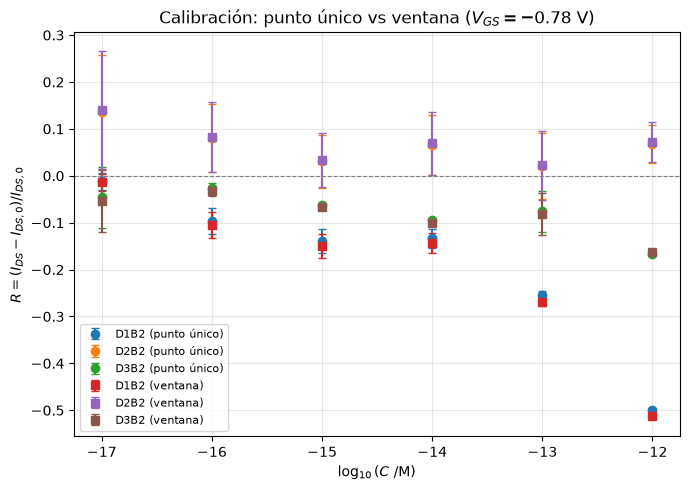

In [256]:
# --- Extracción: media de ventana por curva (todas las réplicas) ---
rows = []
for m in transfer_measurements:
    curves = [c for c in read_all_curves(hdf5_path, m, direction='fwd')
              if len(c['v_gs']) >= MIN_POINTS]
    pts = np.array([i_ds_window_mean(c['v_gs'], c['i_ds'], V_READ, V_WINDOW, V_WINDOW_SIDE)
                    for c in curves],
                   dtype=float)
    if pts.size == 0:
        continue
    dev, _, cond, _ = parse_measurement_name(m)
    rows.append({
        'measurement': m,
        'device': dev,
        'condition': cond,
        'conc': cond_conc(cond),
        'n_replicas': int(pts.size),
        'i1': _safe_get(pts, 0), 'i2': _safe_get(pts, 1), 'i3': _safe_get(pts, 2),
        'mean': float(np.mean(pts)),
        'sd': float(np.std(pts, ddof=1)) if pts.size > 1 else 0.0,
    })

df_win_raw = pd.DataFrame(rows)
df_win = collapse_conditions(df_win_raw)

# --- Normalización contra la Ref del mismo dispositivo ---
df_win['R'] = np.nan
df_win['R_sd'] = np.nan
for dev, grp in df_win.groupby('device'):
    i_ref = grp.loc[grp['condition'] == 'Ref', 'mean'].iloc[0]
    df_win.loc[grp.index, 'R'] = (grp['mean'] - i_ref) / i_ref
    df_win.loc[grp.index, 'R_sd'] = grp['sd'] / abs(i_ref)

df_win

# --- Curva de calibración: punto único (3.1) vs ventana (3.2) ---
cal1 = df_pts[df_pts['condition'] != 'Ref'].copy()      # df_pts viene de 3.1
cal1['logC'] = np.log10(cal1['conc'])
cal2 = df_win[df_win['condition'] != 'Ref'].copy()
cal2['logC'] = np.log10(cal2['conc'])

fig, ax = plt.subplots(figsize=(7, 5))
for dev, grp in cal1.groupby('device'):
    grp = grp.sort_values('logC')
    ax.errorbar(grp['logC'], grp['R'], yerr=grp['R_sd'],
                marker='o', ls='none', capsize=3, label=f'{dev} (punto único)')
for dev, grp in cal2.groupby('device'):
    grp = grp.sort_values('logC')
    ax.errorbar(grp['logC'], grp['R'], yerr=grp['R_sd'],
                marker='s', ls='none', capsize=3, label=f'{dev} (ventana)')

ax.axhline(0, color='gray', ls='--', lw=0.8)
ax.set_xlabel(r'$\log_{10}(C\ /\mathrm{M})$')
ax.set_ylabel(r'$R = (I_{DS} - I_{DS,0}) / I_{DS,0}$')
ax.set_title(f'Calibración: punto único vs ventana ($V_{{GS}}={V_READ}$ V)')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


### 3.3 Ajuste lineal-log y sensibilidad

Los métodos 3.1 y 3.2 producen, para cada dispositivo, una serie de valores $R$ en
función de $C$. El último paso es ajustar esos datos con una **recta en escala
semi-logarítmica**:

$$
R = a + b \log_{10}(C)
$$

donde $b$ es la **sensibilidad** (cambio de $R$ por década de concentración) y $a$
el intercepto. El modelo se puede invertir para estimar una concentración
desconocida:

$$
C = 10^{(R-a)/b}
$$

Como $R$ es adimensional, $b$ se expresa por década; si se multiplica $R$ por 100,
$b$ queda en % por década.

Para cada dispositivo se ajusta su propia recta (no se promedian dispositivos,
porque pueden responder con signo contrario). De cada ajuste se reportan:

- la pendiente $b$ (sensibilidad),
- el coeficiente $R^2$ (grado de ajuste).

> El artículo determina la sensibilidad precisamente como la pendiente de la curva
> de calibración, y de ella deriva el límite de detección `LoD = 3.3·σ_r / b`, con
> `σ_r` la desviación de los residuos.


Pendiente de la calibración (sensibilidad), por dispositivo:
  D1B2:  punto único  b=-0.0830  R²=0.826   |   ventana  b=-0.0849  R²=0.834
  D2B2:  punto único  b=-0.0139  R²=0.402   |   ventana  b=-0.0141  R²=0.396
  D3B2:  punto único  b=-0.0223  R²=0.728   |   ventana  b=-0.0208  R²=0.724


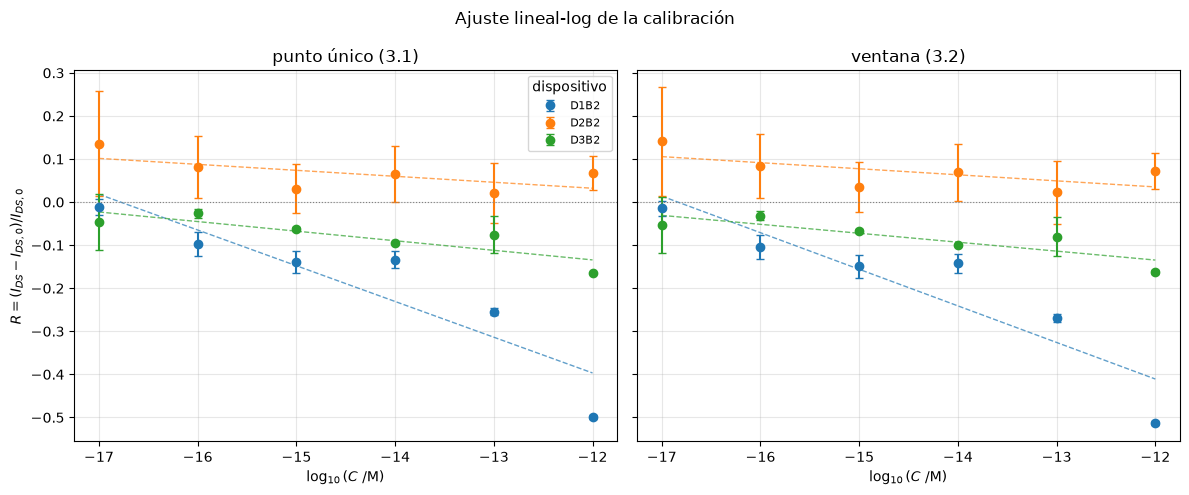

In [257]:
# === 3.3 Pendiente de ajuste lineal-log ===
# Ajustamos R = a + b * log10(C). La pendiente b es la sensibilidad
# (cambio de R por década de concentración).

from scipy.stats import linregress

def log_fit(cal_df):
    """Ajuste lineal R vs log10(C), por dispositivo. Devuelve {dev: res}."""
    fits = {}
    for dev, grp in cal_df.groupby('device'):
        grp = grp.sort_values('logC')
        fits[dev] = linregress(grp['logC'], grp['R'])
    return fits

# Datos de calibración (sin la Ref) de los métodos 3.1 y 3.2
cal_pt = df_pts[df_pts['condition'] != 'Ref'].copy()
cal_pt['logC'] = np.log10(cal_pt['conc'])
cal_win = df_win[df_win['condition'] != 'Ref'].copy()
cal_win['logC'] = np.log10(cal_win['conc'])

fits_pt = log_fit(cal_pt)
fits_win = log_fit(cal_win)

# --- Reporte: pendiente (sensibilidad) y R² ---
print('Pendiente de la calibración (sensibilidad), por dispositivo:')
for dev in sorted(fits_pt):
    b_pt, r_pt = fits_pt[dev].slope, fits_pt[dev].rvalue**2
    b_win, r_win = fits_win[dev].slope, fits_win[dev].rvalue**2
    print(f'  {dev}:  punto único  b={b_pt:+.4f}  R²={r_pt:.3f}   |   ventana  b={b_win:+.4f}  R²={r_win:.3f}')

# --- Visualización: datos + recta ajustada ---
dev_colors = {dev: plt.cm.tab10(i) for i, dev in enumerate(sorted(cal_pt['device'].unique()))}

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, (cal, fits, titulo) in zip(
        axes,
        [(cal_pt, fits_pt, 'punto único (3.1)'), (cal_win, fits_win, 'ventana (3.2)')]):
    for dev, grp in cal.groupby('device'):
        grp = grp.sort_values('logC')
        color = dev_colors[dev]
        ax.errorbar(grp['logC'], grp['R'], yerr=grp['R_sd'], ls='none',
                    marker='o', ms=6, capsize=3, color=color, label=dev)
        xs = np.linspace(grp['logC'].min(), grp['logC'].max(), 50)
        ax.plot(xs, fits[dev].slope * xs + fits[dev].intercept,
                '--', lw=1, color=color, alpha=0.7)
    ax.axhline(0, color='gray', ls=':', lw=0.8)
    ax.set_xlabel(r'$\log_{10}(C\ /\mathrm{M})$')
    ax.set_title(titulo)
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel(r'$R = (I_{DS} - I_{DS,0}) / I_{DS,0}$')
axes[0].legend(title='dispositivo', fontsize=8)
fig.suptitle('Ajuste lineal-log de la calibración')
fig.tight_layout()
plt.show()


### 3.4 Curva del batch y reproducibilidad

Los ajustes de 3.3 describen cada dispositivo por separado. El siguiente paso es
construir **una sola curva de calibración para el batch**, promediando los
dispositivos. La dispersión relevante aquí ya no es la repetibilidad técnica, sino la
**reproducibilidad entre dispositivos**.

El promedio se hace en dos niveles, para no mezclar las dos fuentes de dispersión:

1. Para cada dispositivo $d$ y concentración $C$, media de sus réplicas técnicas:
   $\bar R_{d,C}$.
2. Para el batch, media de las medias de los dispositivos:
   $\bar R_C = \frac{1}{N}\sum_d \bar R_{d,C}$.

La barra de error es la **SD entre las medias de los dispositivos**:

$$
s_C = \mathrm{std}\big(\bar R_{1,C},\dots,\bar R_{N,C}\big)
$$

con $N$ dispositivos y `ddof=1`. En la tabla se incluye también el error estándar
$\mathrm{SEM}=s_C/\sqrt{N}$, pero la figura usa la SD, que es la que describe la
dispersión entre dispositivos.

Dos aclaraciones:

- El `Ref` no entra en la tabla del batch: por construcción $R=0$ en todos los
  dispositivos y su incertidumbre es puramente técnica.
- Con $N=3$ la SD es ruidosa. Por eso se reporta $N$ en cada concentración y se
  acompaña del SEM.

Si se quiere repetir la curva sin algún dispositivo, basta con cambiar
`EXCLUDE_DEVICES` en la celda siguiente (por ejemplo `['D2']`). No hace falta tocar
nada más.


In [258]:
# === 3.4 Curva del batch y reproducibilidad ===
# Si se quiere excluir un dispositivo de la curva del batch, agregarlo aquí.
EXCLUDE_DEVICES = []   # p. ej. ['D2'] excluye D2B2, D2B3, ...


def excluded_mask(devices, exclude=()):
    """True para los dispositivos que coinciden exacta o por prefijo (D2)."""
    exclude = set(exclude)
    return devices.apply(lambda d: d in exclude or str(d).split('B')[0] in exclude)


def batch_curve(df_device, exclude=()):
    """Una fila por concentración con la media y la SD entre dispositivos.

    Entrada: `df_pts` o `df_win` (una fila por dispositivo+condición).
    La media es de las medias por dispositivo, no de todas las réplicas.
    El `Ref` se excluye: por definición R=0 en todos los dispositivos.
    """
    d = df_device[(df_device['condition'] != 'Ref') &
                  (~excluded_mask(df_device['device'], exclude))].copy()

    rows = []
    for conc, grp in d.groupby('conc'):
        r = grp['R'].to_numpy(dtype=float)
        n = r.size
        sd = float(np.std(r, ddof=1)) if n > 1 else float('nan')
        rows.append({
            'condition': grp['condition'].iloc[0],
            'conc': float(conc),
            'logC': float(np.log10(conc)),
            'n_devices': int(n),
            'R_mean': float(np.mean(r)),
            'R_sd': sd,
            'R_sem': sd / np.sqrt(n) if n > 1 else float('nan'),
            'devices': ', '.join(sorted(grp['device'])),
        })

    return pd.DataFrame(rows).sort_values('logC').reset_index(drop=True)


df_batch_pts = batch_curve(df_pts, EXCLUDE_DEVICES)
df_batch_win = batch_curve(df_win, EXCLUDE_DEVICES)

print(f'Dispositivos excluidos: {EXCLUDE_DEVICES or "ninguno"}')
print('\nCurva del batch — punto único (3.1):')
display(df_batch_pts)
print('\nCurva del batch — ventana (3.2):')
display(df_batch_win)


Dispositivos excluidos: ninguno

Curva del batch — punto único (3.1):


,condition,conc,logC,n_devices,R_mean,R_sd,R_sem,devices
0,E-17,1.000000e-17,-17.0,3,0.025903,0.096638,0.055794,"D1B2, D2B2, D3B2"
1,E-16,1.000000e-16,-16.0,3,-0.014190,0.089338,0.051579,"D1B2, D2B2, D3B2"
2,E-15,1.000000e-15,-15.0,3,-0.057271,0.085535,0.049384,"D1B2, D2B2, D3B2"
3,E-14,1.000000e-14,-14.0,3,-0.054263,0.105276,0.060781,"D1B2, D2B2, D3B2"
4,E-13,1.000000e-13,-13.0,3,-0.103416,0.139585,0.080590,"D1B2, D2B2, D3B2"
5,E-12,1.000000e-12,-12.0,3,-0.199042,0.284986,0.164537,"D1B2, D2B2, D3B2"



Curva del batch — ventana (3.2):


,condition,conc,logC,n_devices,R_mean,R_sd,R_sem,devices
0,E-17,1.000000e-17,-17.0,3,0.024349,0.102836,0.059372,"D1B2, D2B2, D3B2"
1,E-16,1.000000e-16,-16.0,3,-0.017674,0.094942,0.054815,"D1B2, D2B2, D3B2"
2,E-15,1.000000e-15,-15.0,3,-0.060665,0.091980,0.053105,"D1B2, D2B2, D3B2"
3,E-14,1.000000e-14,-14.0,3,-0.058018,0.111991,0.064658,"D1B2, D2B2, D3B2"
4,E-13,1.000000e-13,-13.0,3,-0.109010,0.147307,0.085048,"D1B2, D2B2, D3B2"
5,E-12,1.000000e-12,-12.0,3,-0.200829,0.293955,0.169715,"D1B2, D2B2, D3B2"


#### Ajuste de la curva del batch

Con la media y la SD entre dispositivos se ajusta una única recta por método, con el
mismo modelo lineal-log de 3.3:

$$
\bar R_C = a + b \log_{10}(C)
$$

El ajuste es **OLS no ponderado** sobre las medias del batch: cada concentración pesa
igual y la SD se usa para visualizar la dispersión, no para pesar el ajuste.

Para comparar, se reportan también las pendientes por dispositivo de 3.3. La
dispersión de esas pendientes es una medida directa de la reproducibilidad de la
sensibilidad.

> El $R^2$ del batch se calcula sobre las medias de las concentraciones, no sobre los
> puntos individuales de cada dispositivo. Por eso no es directamente comparable con
> el $R^2$ por dispositivo.


Reproducibilidad de la sensibilidad (SD de b entre dispositivos):
  Punto   : SD(b_dispositivos)=0.0377   b_batch=-0.0397
  Ventana : SD(b_dispositivos)=0.0391   b_batch=-0.0399


,metodo,nivel,b,se_b,R2,n
0,Punto,D1B2,-0.0830,0.0191,0.826,6
1,Punto,D2B2,-0.0139,0.0085,0.402,6
2,Punto,D3B2,-0.0223,0.0068,0.728,6
3,Punto,Batch,-0.0397,0.0064,0.906,6
4,Ventana,D1B2,-0.0849,0.0190,0.834,6
5,Ventana,D2B2,-0.0141,0.0087,0.396,6
6,Ventana,D3B2,-0.0208,0.0064,0.724,6
7,Ventana,Batch,-0.0399,0.0061,0.914,6


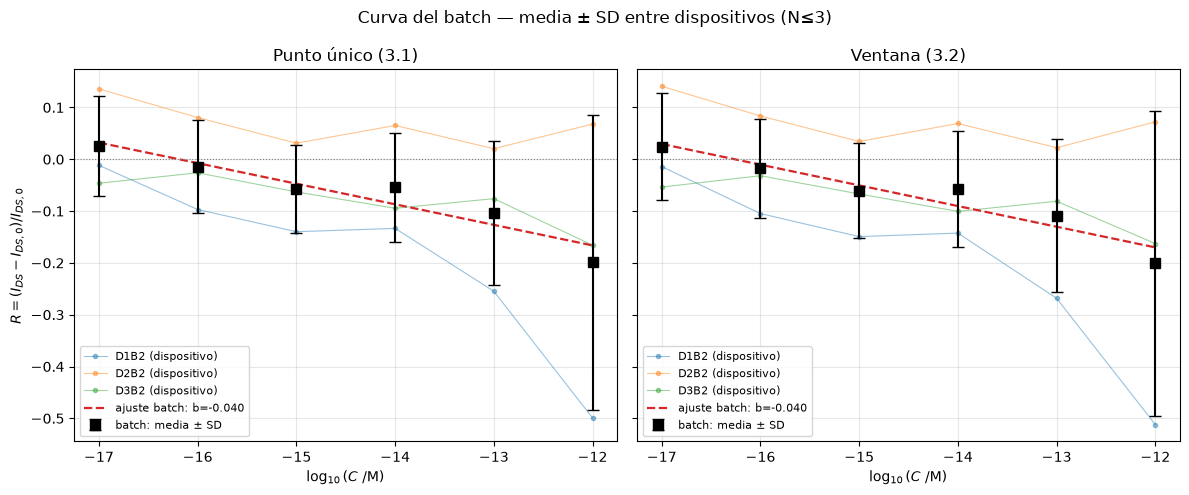

In [259]:
# --- Ajuste OLS no ponderado de la curva del batch ---
from scipy.stats import linregress


def fit_summary(nivel, x, y):
    """Ajuste y = a + b x y resumen de métricas."""
    res = linregress(np.asarray(x, dtype=float), np.asarray(y, dtype=float))
    return {
        'nivel': nivel,
        'b': res.slope,
        'se_b': res.stderr,
        'R2': res.rvalue ** 2,
        'n': int(len(x)),
    }


# --- Comparación: por dispositivo vs batch ---
rows = []
for metodo, df_dev, df_batch in [('Punto', df_pts, df_batch_pts),
                                 ('Ventana', df_win, df_batch_win)]:
    cal = df_dev[(df_dev['condition'] != 'Ref') &
                 (~excluded_mask(df_dev['device'], EXCLUDE_DEVICES))].copy()
    cal['logC'] = np.log10(cal['conc'])
    for dev, grp in cal.groupby('device'):
        grp = grp.sort_values('logC')
        rows.append({'metodo': metodo,
                     **fit_summary(dev, grp['logC'], grp['R'])})
    rows.append({'metodo': metodo,
                 **fit_summary('Batch', df_batch['logC'], df_batch['R_mean'])})

df_fit_batch = pd.DataFrame(rows)[['metodo', 'nivel', 'b', 'se_b', 'R2', 'n']]

print('Reproducibilidad de la sensibilidad (SD de b entre dispositivos):')
for metodo, grp in df_fit_batch.groupby('metodo'):
    dev = grp[grp['nivel'] != 'Batch']['b'].to_numpy()
    b_batch = grp.loc[grp['nivel'] == 'Batch', 'b'].iloc[0]
    print(f'  {metodo:8s}: SD(b_dispositivos)={np.std(dev, ddof=1):.4f}   '
          f'b_batch={b_batch:+.4f}')

display(df_fit_batch.round({'b': 4, 'se_b': 4, 'R2': 3}))

# --- Figura: dispositivos + media del batch ± SD + ajuste ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, (nombre, df_dev, df_batch) in zip(
        axes,
        [('Punto único (3.1)', df_pts, df_batch_pts),
         ('Ventana (3.2)', df_win, df_batch_win)]):

    cal = df_dev[(df_dev['condition'] != 'Ref') &
                 (~excluded_mask(df_dev['device'], EXCLUDE_DEVICES))].copy()
    cal['logC'] = np.log10(cal['conc'])
    for k, (dev, grp) in enumerate(cal.groupby('device')):
        grp = grp.sort_values('logC')
        ax.plot(grp['logC'], grp['R'], 'o-', ms=3, lw=0.8, alpha=0.45,
                color=plt.cm.tab10(k), label=f'{dev} (dispositivo)')

    ax.errorbar(df_batch['logC'], df_batch['R_mean'], yerr=df_batch['R_sd'],
                fmt='s', ms=7, color='k', capsize=4, zorder=4,
                label='batch: media ± SD')

    res = linregress(df_batch['logC'], df_batch['R_mean'])
    xs = np.linspace(df_batch['logC'].min(), df_batch['logC'].max(), 100)
    ax.plot(xs, res.intercept + res.slope * xs, '--', color='C3', lw=1.6,
            label=f'ajuste batch: b={res.slope:+.3f}')

    ax.axhline(0, color='gray', ls=':', lw=0.8)
    ax.set_xlabel(r'$\log_{10}(C\ /\mathrm{M})$')
    ax.set_title(nombre)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, loc='best')

axes[0].set_ylabel(r'$R = (I_{DS} - I_{DS,0}) / I_{DS,0}$')
n_max = int(df_batch_pts['n_devices'].max())
fig.suptitle(f'Curva del batch — media ± SD entre dispositivos (N≤{n_max})')
fig.tight_layout()
plt.show()


#### Cómo leer la curva del batch

La recta del batch resume la respuesta media del conjunto de dispositivos. Si las
líneas individuales quedan alrededor de esa recta y las barras de SD son pequeñas
frente al cambio total de $R$, la reproducibilidad entre dispositivos es buena.

Si un dispositivo se separa de forma sistemática, la media del batch sigue siendo
válida como resumen, pero conviene reportar también su pendiente individual. En un
caso real, ese dispositivo puede excluirse añadiéndolo a `EXCLUDE_DEVICES` y
comparando ambas curvas.

La SD entre dispositivos no mide el ruido de una medición concreta: mide cuánto
difieren las medias de dispositivos distintos. Para el ruido técnico está la SD de
las réplicas que se usa en 3.1–3.3.
